<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/17-deep-learning-pytorch/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 17: Deep Learning with PyTorch

This module starts Part 3: deep learning and modern AI. Everything in it, from image recognition to large language models, rests on the same small set of ideas: **tensors** to hold data, **automatic differentiation** to compute gradients, **layers** stacked into a network, and a **training loop** that nudges millions of numbers downhill. In Module 9 you built automatic differentiation by hand with a tiny `Value` class. PyTorch does the same thing, for arrays of any size, on a CPU or a GPU.

By the end of this module you'll be able to write, train, debug and save a neural network in PyTorch, and you'll know the techniques that make the difference between a network that trains and one that doesn't: good initialisation, normalisation, dropout, learning-rate schedules, and a systematic way to find bugs.

**Contents**

1. What deep learning is
2. Tensors
3. Autograd: gradients for free
4. The training loop, by hand
5. `nn.Module`: building networks
6. Datasets and data loaders
7. Classification: logits and cross-entropy
8. Optimisers
9. Initialisation
10. Normalisation
11. Overfitting: dropout, weight decay and early stopping
12. Learning-rate schedules
13. GPUs and devices
14. Debugging training
15. Saving and loading

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import torch
from torch import nn

print("PyTorch", torch.__version__)
_ = torch.manual_seed(0)            # manual_seed returns a generator object; "_ =" just hides it

PyTorch 2.15.0+cu132


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

PyTorch comes pre-installed on Google Colab. On your own computer, install it with `pip install torch` (the [PyTorch website](https://pytorch.org/get-started/locally/) gives the right command for your system and graphics card). Everything in this module runs on an ordinary CPU in a few seconds per section.

## 1. What deep learning is

A **neural network** is a function built from simple pieces. The most common piece is a **layer**: a linear transformation (multiply by a matrix of weights, add a vector of biases) followed by a simple non-linear function such as `max(0, x)`, called **ReLU**. Stack several layers, and each one transforms the output of the one before:

$$\text{input} \rightarrow \text{linear} \rightarrow \text{ReLU} \rightarrow \text{linear} \rightarrow \text{ReLU} \rightarrow \text{linear} \rightarrow \text{output}$$

Two facts make this powerful:

- **Without the non-linear functions, stacking layers would be pointless**: a linear function of a linear function is still linear, so the whole network would be one big linear model. The non-linearities let each layer bend the space a little, and many small bends can approximate almost any shape.
- **Every weight is learnt the same way**: compute the loss, compute the gradient of the loss with respect to every weight (by backpropagation, Module 9), and move each weight a little downhill. That's gradient descent, and it scales from a few weights to hundreds of billions.

"Deep" just means many layers. Deep learning took over image, speech and language tasks from around 2012, when large datasets, graphics cards and a few training tricks (several of which are in this module) came together.

## 2. Tensors

A **tensor** is PyTorch's array: like a NumPy array (Module 6), with two additions. It can live on a GPU, and it can remember how it was computed, so gradients can flow back through it.

In [3]:
a = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print(a)
print("shape:", a.shape, "  dtype:", a.dtype, "  device:", a.device)
print()
print("zeros:", torch.zeros(2, 3).shape, "  random normal:", torch.randn(2, 3).shape, "  range:", torch.arange(5))

tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3])   dtype: torch.float32   device: cpu

zeros: torch.Size([2, 3])   random normal: torch.Size([2, 3])   range: tensor([0, 1, 2, 3, 4])


Almost everything from NumPy carries over, often with the same names: element-wise arithmetic, broadcasting, indexing, reductions and matrix multiplication with `@`.

In [4]:
b = torch.tensor([10.0, 20.0, 30.0])
print("broadcasting a + b:\n", a + b)
print("column means:", a.mean(dim=0))                    # PyTorch says dim where NumPy says axis
print("a @ a.T:\n", a @ a.T)
print("second column:", a[:, 1])
print("reshape to (3, 2):\n", a.reshape(3, 2))

broadcasting a + b:
 tensor([[11., 22., 33.],
        [14., 25., 36.]])
column means: tensor([2.5000, 3.5000, 4.5000])
a @ a.T:
 tensor([[14., 32.],
        [32., 77.]])
second column: tensor([2., 5.])
reshape to (3, 2):
 tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])


Three details trip people up:

- **dtype.** Neural networks normally use 32-bit floats (`torch.float32`), not NumPy's default 64-bit. `torch.tensor([1, 2])` is an integer tensor, and integer tensors can't have gradients. Class labels, on the other hand, must be integers (`torch.long`).
- **Converting to and from NumPy.** `torch.from_numpy(array)` and `tensor.numpy()` **share memory** with the original: changing one changes the other. `torch.tensor(array)` makes a copy.
- **Shapes.** Most PyTorch layers expect the first dimension to be the **batch**: a tensor of 32 images of 28 × 28 pixels has shape `(32, 28, 28)` or, with a colour channel, `(32, 1, 28, 28)`. Shape mistakes are the most common bug in deep learning code, so print shapes often.

In [5]:
array = np.array([1.0, 2.0, 3.0])
shared = torch.from_numpy(array)
copied = torch.tensor(array)
array[0] = 100.0
print("from_numpy (shares memory):", shared)
print("tensor (a copy):           ", copied)
print("dtype from NumPy:", shared.dtype, "  converted:", shared.float().dtype)

from_numpy (shares memory): tensor([100.,   2.,   3.], dtype=torch.float64)
tensor (a copy):            tensor([1., 2., 3.], dtype=torch.float64)
dtype from NumPy: torch.float64   converted: torch.float32


## 3. Autograd: gradients for free

Set `requires_grad=True` on a tensor and PyTorch records every operation done with it, building a graph of the computation. Calling `.backward()` on a scalar result walks that graph backwards and stores the derivative in each tensor's `.grad`. It's exactly the `Value` class from Module 9, built into every tensor.

In [6]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2 + 2 * x + 1          # y = (x + 1)²
y.backward()                     # compute dy/dx
print(f"y = {y.item()}, dy/dx at x = 3: {x.grad.item()}   (by hand: 2x + 2 = {2 * 3 + 2})")

y = 16.0, dy/dx at x = 3: 8.0   (by hand: 2x + 2 = 8)


It works through any chain of operations, including matrix products, and for every input at once. Here's the gradient of a squared error with respect to a whole weight vector, checked against the formula from Module 12:

In [7]:
torch.manual_seed(0)
X = torch.randn(100, 3)
y_true = X @ torch.tensor([2.0, -1.0, 0.5]) + 0.1 * torch.randn(100)
w = torch.zeros(3, requires_grad=True)

loss = ((X @ w - y_true) ** 2).mean()
loss.backward()
by_hand = 2 * X.T @ (X @ w.detach() - y_true) / len(X)
print("autograd:", w.grad)
print("by hand: ", by_hand)

autograd: tensor([-3.0782,  1.2198, -0.5286])
by hand:  tensor([-3.0782,  1.2198, -0.5286])


Three rules of autograd that matter in practice:

1. **Gradients accumulate.** Each call to `.backward()` **adds** to `.grad` rather than replacing it. That's why every training loop clears the gradients before each step (`optimizer.zero_grad()`). Forgetting it is a classic bug: the gradients grow with every step.
2. **Turn tracking off when you don't need gradients.** Inside `with torch.no_grad():`, operations aren't recorded, which saves memory and time. Use it for evaluation and for updating weights by hand.
3. **`.detach()`** gives a tensor with the same values but cut off from the graph, for when you want to use a value without gradients flowing back through it.

In [8]:
w.grad = None                       # start fresh
for _ in range(3):
    loss = ((X @ w - y_true) ** 2).mean()
    loss.backward()                 # without clearing, the gradient adds up
    print("accumulated gradient:", w.grad.numpy().round(3))

accumulated gradient: [-3.078  1.22  -0.529]
accumulated gradient: [-6.156  2.44  -1.057]
accumulated gradient: [-9.235  3.66  -1.586]


The same gradient, added three times. In a training loop, that would mean steps three times too big, then four, then five.

## 4. The training loop, by hand

Every neural network is trained with the same loop:

1. **Forward**: compute predictions and the loss on a batch.
2. **Backward**: compute the gradients with `loss.backward()`.
3. **Step**: move every weight a little against its gradient.
4. **Zero**: clear the gradients for the next step.

Here it is with nothing but tensors and autograd, fitting the linear model above:

learnt weights: [ 2.001 -0.995  0.489]  bias: 0.024   (true: 2, -1, 0.5, 0)


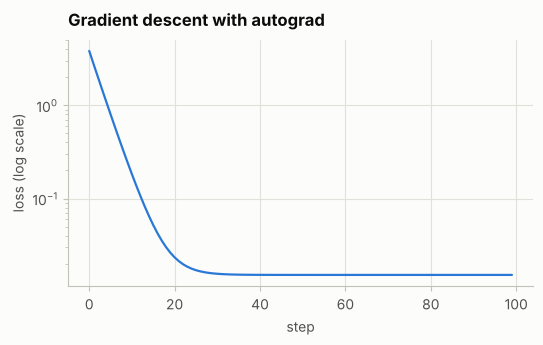

In [9]:
w = torch.zeros(3, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
learning_rate = 0.1
history = []
for step in range(100):
    prediction = X @ w + b                      # 1. forward
    loss = ((prediction - y_true) ** 2).mean()
    loss.backward()                              # 2. backward
    with torch.no_grad():                        # 3. step (don't record the update itself)
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad
    w.grad.zero_()                               # 4. zero
    b.grad.zero_()
    history.append(loss.item())

print("learnt weights:", w.detach().numpy().round(3), " bias:", round(b.item(), 3), "  (true: 2, -1, 0.5, 0)")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(history, color=PALETTE[0])
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("loss (log scale)")
ax.set_title("Gradient descent with autograd")
plt.show()

PyTorch packages each part of this loop: `nn.Linear` holds `w` and `b`, `nn.MSELoss` computes the loss, and an **optimiser** does steps 3 and 4. The same loop, written the way you'll write every training loop from now on:

In [10]:
model = nn.Linear(3, 1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for step in range(100):
    optimizer.zero_grad()                        # clear old gradients
    loss = loss_fn(model(X).squeeze(1), y_true)   # forward
    loss.backward()                              # backward
    optimizer.step()                             # update every parameter

print("weights:", model.weight.detach().numpy().round(3), " bias:", model.bias.detach().numpy().round(3))

weights: [[ 2.001 -0.995  0.489]]  bias: [0.024]


The same answer. `model(X)` has shape `(100, 1)` (one output per example), so `.squeeze(1)` removes the extra dimension to match `y_true`, which has shape `(100,)`. Without it, the loss would broadcast `(100, 1)` against `(100,)` into a `(100, 100)` table and compute nonsense without any error, which is one of the nastiest silent bugs in PyTorch. Recent versions print a warning about it; always check that predictions and targets have the same shape.

## 5. `nn.Module`: building networks

Networks in PyTorch are classes that inherit from `nn.Module` (classes and inheritance were Module 3). You create the layers in `__init__` and say how data flows through them in `forward`. PyTorch then finds every learnable parameter automatically.

In [11]:
class MLP(nn.Module):
    """A multilayer perceptron: linear layers with ReLU between them."""

    def __init__(self, n_inputs, n_hidden, n_outputs):
        super().__init__()
        self.hidden1 = nn.Linear(n_inputs, n_hidden)
        self.hidden2 = nn.Linear(n_hidden, n_hidden)
        self.output = nn.Linear(n_hidden, n_outputs)

    def forward(self, x):
        x = torch.relu(self.hidden1(x))
        x = torch.relu(self.hidden2(x))
        return self.output(x)


net = MLP(64, 128, 10)
print(net)
print()
for name, p in net.named_parameters():
    print(f"{name:<16} {str(tuple(p.shape)):<12} {p.numel():>6,} numbers")
print(f"total: {sum(p.numel() for p in net.parameters()):,} learnable parameters")

MLP(
  (hidden1): Linear(in_features=64, out_features=128, bias=True)
  (hidden2): Linear(in_features=128, out_features=128, bias=True)
  (output): Linear(in_features=128, out_features=10, bias=True)
)

hidden1.weight   (128, 64)     8,192 numbers
hidden1.bias     (128,)          128 numbers
hidden2.weight   (128, 128)   16,384 numbers
hidden2.bias     (128,)          128 numbers
output.weight    (10, 128)     1,280 numbers
output.bias      (10,)            10 numbers
total: 26,122 learnable parameters


Each `nn.Linear(n_in, n_out)` holds a weight matrix of shape `(n_out, n_in)` and a bias of length `n_out`. Calling `net(x)` runs `forward` (never call `forward` directly; calling the module also runs some bookkeeping).

For networks that are just a sequence of layers, `nn.Sequential` saves writing a class:

In [12]:
same_net = nn.Sequential(
    nn.Linear(64, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
print(same_net)
print("output shape for a batch of 5:", same_net(torch.randn(5, 64)).shape)

Sequential(
  (0): Linear(in_features=64, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=10, bias=True)
)
output shape for a batch of 5: torch.Size([5, 10])


## 6. Datasets and data loaders

Real datasets are trained in **mini-batches**: a few dozen to a few hundred examples per step, rather than all the data at once (too slow and memory-hungry) or one example at a time (too noisy and slow on modern hardware). Each pass through the whole dataset is an **epoch**.

PyTorch splits this into two pieces:

- a **Dataset** knows how many examples there are and how to get example number `i`
- a **DataLoader** draws batches from a dataset, shuffling the order each epoch

For data that fits in memory, `TensorDataset` wraps tensors directly. We'll use the handwritten digits from Module 15: 1,797 images of 8 × 8 pixels.

In [13]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

digits = load_digits()
X_np = digits.data.astype(np.float32) / 16.0          # pixel values 0 to 16, scaled to 0 to 1
y_np = digits.target
X_tr, X_va, y_tr, y_va = train_test_split(X_np, y_np, test_size=0.3, stratify=y_np, random_state=0)

train_set = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr).long())
valid_set = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va).long())
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=256)

xb, yb = next(iter(train_loader))
print(f"training examples: {len(train_set)}   batches per epoch: {len(train_loader)}")
print("one batch:", xb.shape, xb.dtype, yb.shape, yb.dtype)

training examples: 1257   batches per epoch: 40
one batch: torch.Size([32, 64]) torch.float32 torch.Size([32]) torch.int64


For data that doesn't fit in memory, such as millions of image files, you write your own `Dataset` class with `__len__` and `__getitem__` (the dataset loader you built in Module 3 is exactly this pattern), and the DataLoader can load batches in parallel with `num_workers`.

Shuffle the training data so each batch is a fair sample and the order changes every epoch; don't shuffle validation data (it doesn't matter, and fixed order makes results easier to compare).

## 7. Classification: logits and cross-entropy

For classification, the network's final layer outputs one number per class, called **logits**: unnormalised scores. The **softmax** function turns them into probabilities (Module 9), and the **cross-entropy** loss is the negative log of the probability given to the true class.

PyTorch's `nn.CrossEntropyLoss` takes the **raw logits** and does the softmax inside, in a numerically stable way. Don't add a softmax layer at the end of the network: the loss would apply it twice and train badly.

Now a full training run, with the two functions every project needs: one epoch of training, and an evaluation.

In [14]:
def train_epoch(model, loader, loss_fn, optimizer):
    model.train()                                   # training mode (matters for dropout and batch norm)
    total, count = 0.0, 0
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
        count += len(xb)
    return total / count


@torch.no_grad()                                    # no gradients needed for evaluation
def evaluate(model, loader, loss_fn):
    model.eval()                                    # evaluation mode
    total, correct, count = 0.0, 0, 0
    for xb, yb in loader:
        logits = model(xb)
        total += loss_fn(logits, yb).item() * len(xb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        count += len(xb)
    return total / count, correct / count


def fit(model, epochs, optimizer, loss_fn=nn.CrossEntropyLoss(), scheduler=None, loader=train_loader, quiet=True):
    curves = {"train loss": [], "valid loss": [], "valid accuracy": []}
    for epoch in range(epochs):
        curves["train loss"].append(train_epoch(model, loader, loss_fn, optimizer))
        valid_loss, valid_acc = evaluate(model, valid_loader, loss_fn)
        curves["valid loss"].append(valid_loss)
        curves["valid accuracy"].append(valid_acc)
        if scheduler is not None:
            scheduler.step()
        if not quiet:
            print(f"epoch {epoch + 1:>2}: train loss {curves['train loss'][-1]:.3f}   valid loss {valid_loss:.3f}   valid accuracy {valid_acc:.3f}")
    return curves


torch.manual_seed(0)
model = MLP(64, 128, 10)
curves = fit(model, epochs=10, optimizer=torch.optim.Adam(model.parameters(), lr=1e-3), quiet=False)

epoch  1: train loss 2.058   valid loss 1.574   valid accuracy 0.837
epoch  2: train loss 1.006   valid loss 0.559   valid accuracy 0.883
epoch  3: train loss 0.416   valid loss 0.328   valid accuracy 0.920
epoch  4: train loss 0.262   valid loss 0.272   valid accuracy 0.935


epoch  5: train loss 0.208   valid loss 0.200   valid accuracy 0.946


epoch  6: train loss 0.177   valid loss 0.176   valid accuracy 0.952
epoch  7: train loss 0.146   valid loss 0.168   valid accuracy 0.954
epoch  8: train loss 0.125   valid loss 0.150   valid accuracy 0.956


epoch  9: train loss 0.105   valid loss 0.142   valid accuracy 0.961
epoch 10: train loss 0.099   valid loss 0.156   valid accuracy 0.941


After a few seconds of training, the network recognises handwritten digits it has never seen with high accuracy. Some details in the code:

- **`model.train()` and `model.eval()`** switch layers that behave differently during training and evaluation (dropout and batch normalisation, sections 10 and 11). Forgetting `model.eval()` is a very common bug.
- **`@torch.no_grad()`** turns off gradient tracking for the whole evaluation function.
- **`loss.item()`** turns a one-number tensor into a Python float. Adding up the tensors themselves would keep every batch's computation graph in memory.
- **The loss is weighted by batch size**, because the last batch is usually smaller than the others.
- **`logits.argmax(dim=1)`** picks the class with the highest score. The largest logit is also the largest probability, so there's no need for a softmax to make predictions.

## 8. Optimisers

Plain gradient descent (SGD) takes a step in the direction of the gradient. Two improvements are used almost everywhere:

- **Momentum** keeps a running average of recent gradients and steps in that direction. It speeds up progress along consistent directions and damps zig-zagging, like a heavy ball rolling downhill.
- **Adam** (Diederik Kingma and Jimmy Ba, 2014) adds a per-parameter step size: it divides each gradient by a running estimate of its typical size, so parameters with small, rare gradients still move. It's the default choice for most deep learning, with `lr=1e-3` as a sensible start. **AdamW** fixes how Adam handles weight decay (section 11) and is the usual choice for large models.

Here are four optimisers on the same network and data, each with a reasonable learning rate:

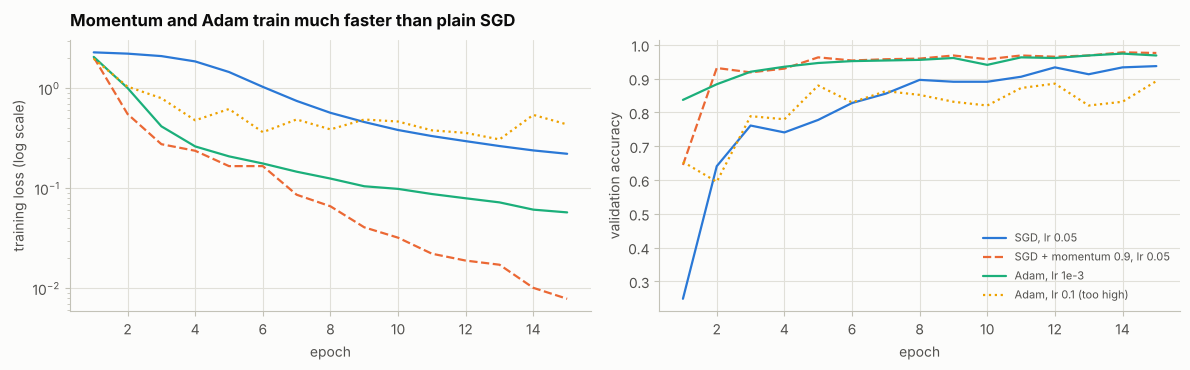

In [15]:
optimisers = {
    "SGD, lr 0.05": lambda p: torch.optim.SGD(p, lr=0.05),
    "SGD + momentum 0.9, lr 0.05": lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "Adam, lr 1e-3": lambda p: torch.optim.Adam(p, lr=1e-3),
    "Adam, lr 0.1 (too high)": lambda p: torch.optim.Adam(p, lr=0.1),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (name, make), colour, style in zip(optimisers.items(), PALETTE, ["-", "--", "-", ":"]):
    torch.manual_seed(0)
    m = MLP(64, 128, 10)
    c = fit(m, epochs=15, optimizer=make(m.parameters()))
    axes[0].plot(range(1, 16), c["train loss"], color=colour, linestyle=style, label=name)
    axes[1].plot(range(1, 16), c["valid accuracy"], color=colour, linestyle=style, label=name)
axes[0].set_yscale("log")
axes[0].set_ylabel("training loss (log scale)")
axes[1].set_ylabel("validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
axes[1].legend(loc="lower right", fontsize=8)
axes[0].set_title("Momentum and Adam train much faster than plain SGD")
fig.tight_layout()
plt.show()

Plain SGD makes slow progress; momentum speeds it up dramatically; Adam is fast with little tuning. And an Adam learning rate 100 times too high trains erratically and ends far worse: **the learning rate is the most important setting in deep learning**. When a network won't train, it's the first thing to check.

## 9. Initialisation

Before training, every weight needs a starting value. It can't be zero: every unit in a layer would compute the same thing, receive the same gradient, and stay identical forever. So weights start random. But the **scale** of that randomness matters enormously in deep networks.

Each layer multiplies its input by a weight matrix. If the weights are a little too large, the signal grows layer after layer and explodes; a little too small, and it shrinks towards zero and vanishes. Gradients flowing backwards suffer the same fate. Here's the size (standard deviation) of the activations through a 20-layer network with three different initialisations:

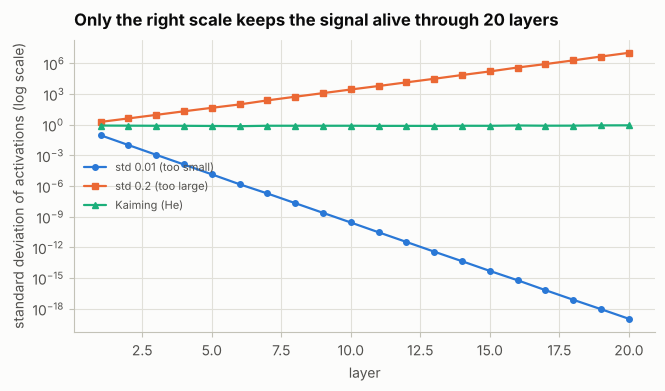

In [16]:
def activation_scales(init, depth=20, width=256):
    torch.manual_seed(0)
    x = torch.randn(512, width)
    scales = []
    for _ in range(depth):
        layer = nn.Linear(width, width, bias=False)
        init(layer.weight)
        x = torch.relu(layer(x))
        scales.append(x.std().item())
    return scales


inits = {
    "std 0.01 (too small)": lambda w: nn.init.normal_(w, std=0.01),
    "std 0.2 (too large)": lambda w: nn.init.normal_(w, std=0.2),
    "Kaiming (He)": lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"),
}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for (name, init), colour, marker in zip(inits.items(), PALETTE, ["o", "s", "^"]):
    ax.plot(range(1, 21), activation_scales(init), color=colour, marker=marker, markersize=4, label=name)
ax.set_yscale("log")
ax.set_xlabel("layer")
ax.set_ylabel("standard deviation of activations (log scale)")
ax.legend(loc="center left", fontsize=8)
ax.set_title("Only the right scale keeps the signal alive through 20 layers")
plt.show()

With a standard deviation of 0.01, the signal shrinks by a constant factor at every layer: after 20 layers it's essentially gone, and so are the gradients. With 0.2, it grows by a constant factor at every layer and explodes to millions. **Kaiming initialisation** (Kaiming He and colleagues, 2015) sets the standard deviation to `√(2 / n_inputs)`, chosen so that, with ReLU, the signal keeps the same size from layer to layer. **Xavier** (or Glorot) initialisation (Xavier Glorot and Yoshua Bengio, 2010) is the equivalent for tanh-like activations.

You rarely need to set this yourself: PyTorch's layers use sensible defaults (`nn.Linear` uses a uniform version scaled by `1 / √n_inputs`). But when you build very deep networks, or write layers yourself, initialisation is the first suspect when training fails to start.

## 10. Normalisation

Even with good initialisation, the scale of activations drifts during training as the weights change. **Normalisation layers** fix it directly: they standardise the activations inside the network, then let the network learn a scale and shift for each feature.

- **Batch normalisation** (Sergey Ioffe and Christian Szegedy, 2015) standardises each feature using the mean and variance of the **current batch**. During training it also keeps a running average of those statistics, and in evaluation mode it uses the running averages instead, so a prediction doesn't depend on the other examples in its batch. This is the main reason `model.eval()` matters.
- **Layer normalisation** (Jimmy Ba, Jamie Kiros and Geoffrey Hinton, 2016) standardises across the features of **each example** separately. It behaves the same in training and evaluation and doesn't depend on the batch size, which is why transformers (Module 19) use it.

Normalisation makes deep networks much easier to train. Here's a 10-layer network trained with SGD, with and without batch normalisation:

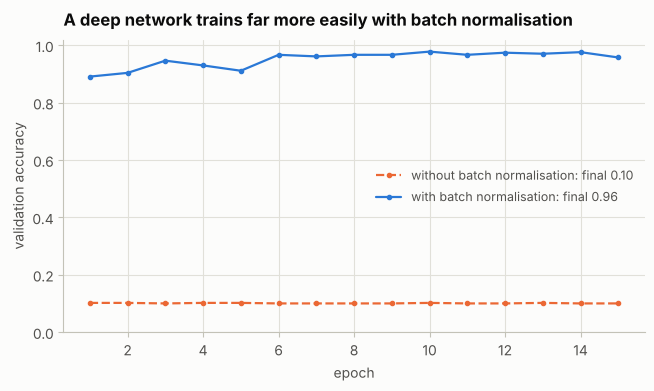

In [17]:
def deep_mlp(norm=None, depth=10, width=128):
    layers, n_in = [], 64
    for _ in range(depth):
        layers.append(nn.Linear(n_in, width))
        if norm == "batch":
            layers.append(nn.BatchNorm1d(width))
        layers.append(nn.ReLU())
        n_in = width
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)


fig, ax = plt.subplots(figsize=(7.5, 3.8))
for norm, colour, style in [(None, PALETTE[1], "--"), ("batch", PALETTE[0], "-")]:
    torch.manual_seed(0)
    m = deep_mlp(norm)
    c = fit(m, epochs=15, optimizer=torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9))
    ax.plot(range(1, 16), c["valid accuracy"], color=colour, linestyle=style, marker="o", markersize=3,
            label=f"{'with' if norm else 'without'} batch normalisation: final {c['valid accuracy'][-1]:.2f}")
ax.set_xlabel("epoch")
ax.set_ylabel("validation accuracy")
ax.set_ylim(0, 1.02)
ax.legend(loc="center right", fontsize=9)
ax.set_title("A deep network trains far more easily with batch normalisation")
plt.show()

Without normalisation, the deep network doesn't train at all in 15 epochs: its accuracy stays at the 10% of random guessing, because the signal and the gradients get lost on the way through ten layers. With batch normalisation, the same network trains quickly and steadily. Normalisation also allows higher learning rates and makes training less sensitive to initialisation, which is why almost every modern deep network uses some form of it.

## 11. Overfitting: dropout, weight decay and early stopping

Neural networks have many parameters (the small MLP above has about 26,000 for 1,257 training images), so they can memorise their training data. The usual signs, from Module 12: training loss keeps falling while validation loss stops improving and then rises.

Three standard defences:

- **Dropout** (Nitish Srivastava, Geoffrey Hinton and colleagues, 2014): during training, set a random fraction of the activations to zero at every step (and scale the rest up to compensate). The network can't rely on any single unit, so it learns more redundant, general features. In evaluation mode, dropout does nothing.
- **Weight decay**: shrink every weight a little at each step, which is L2 regularisation (ridge, Module 12). With Adam, use `AdamW(..., weight_decay=...)`.
- **Early stopping**: keep the model from the epoch with the best validation loss.

To see overfitting clearly, we'll train a large network on just 300 of the digit images, and deliberately give a fifth of them a **wrong**, random label. Real datasets often contain some mislabelled examples, and a network with enough capacity will memorise those too:

training images: 300, of which 57 have a random label (51 of them actually wrong)


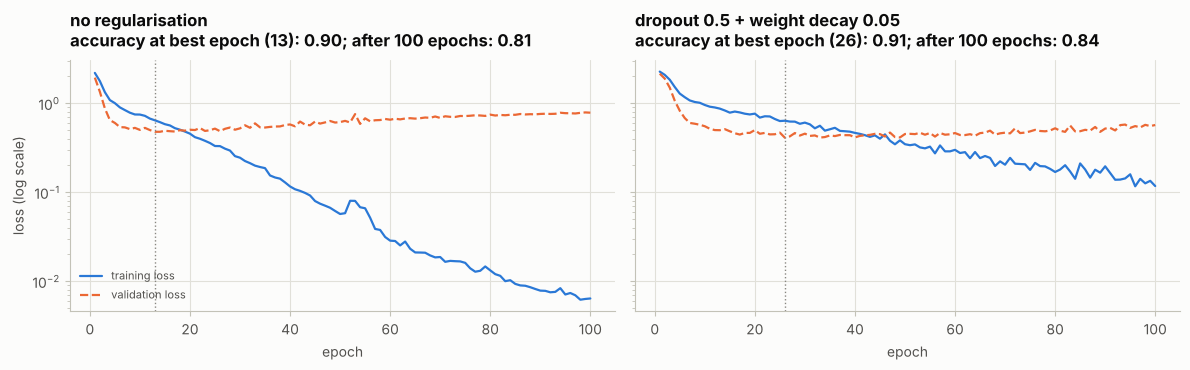

In [18]:
rng = np.random.default_rng(0)
few = rng.choice(len(X_tr), size=300, replace=False)
noisy_labels = y_tr[few].copy()
flip = rng.random(300) < 0.2
noisy_labels[flip] = rng.integers(0, 10, flip.sum())
small_loader = DataLoader(TensorDataset(torch.from_numpy(X_tr[few]), torch.from_numpy(noisy_labels).long()), batch_size=32, shuffle=True)
print(f"training images: 300, of which {flip.sum()} have a random label ({np.sum(noisy_labels[flip] != y_tr[few][flip])} of them actually wrong)")


def wide_net(dropout):
    return nn.Sequential(nn.Linear(64, 512), nn.ReLU(), nn.Dropout(dropout),
                         nn.Linear(512, 512), nn.ReLU(), nn.Dropout(dropout), nn.Linear(512, 10))


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (label, dropout, decay) in zip(axes, [("no regularisation", 0.0, 0.0), ("dropout 0.5 + weight decay 0.05", 0.5, 0.05)]):
    torch.manual_seed(0)
    m = wide_net(dropout)
    c = fit(m, epochs=100, optimizer=torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=decay), loader=small_loader)
    ax.plot(range(1, 101), c["train loss"], color=PALETTE[0], label="training loss")
    ax.plot(range(1, 101), c["valid loss"], color=PALETTE[1], linestyle="--", label="validation loss")
    best = int(np.argmin(c["valid loss"]))
    ax.axvline(best + 1, color=MUTED, linestyle=":", linewidth=1)
    ax.set_title(f"{label}\naccuracy at best epoch ({best + 1}): {c['valid accuracy'][best]:.2f}; after 100 epochs: {c['valid accuracy'][-1]:.2f}")
    ax.set_xlabel("epoch")
    ax.set_yscale("log")
axes[0].set_ylabel("loss (log scale)")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

Without regularisation, the training loss heads towards zero: the network memorises all 300 images, wrong labels included. The validation loss reaches its best early on (the dotted line) and then climbs steadily, and validation accuracy falls with it. With dropout and weight decay, memorising is much slower: the training loss falls more slowly, and the validation loss rises far less, so after 100 epochs the regularised network is ahead.

Notice the dotted lines, though. The **best epoch of the unregularised network** is about as good as anything here. That's **early stopping**: keep the weights from the epoch with the lowest validation loss. It's simple, nearly free, and often the most effective defence of all; in practice it's combined with the others.

The most effective defence, though, isn't on this list: **more data**. The same network trained on all 1,257 images overfits far less. When more real data isn't available, **data augmentation** (Module 18) creates more by transforming the examples you have.

## 12. Learning-rate schedules

A learning rate that's good at the start of training is often too large near the end, when the weights need fine adjustments. A **schedule** changes the learning rate during training. Common shapes:

- **Step decay**: divide the learning rate by 10 at fixed epochs.
- **Cosine annealing** (Ilya Loshchilov and Frank Hutter, 2016): decrease smoothly along a half cosine curve to near zero.
- **Warmup**: start small and increase over the first steps, which stabilises training of large models, especially transformers.
- **One-cycle** (Leslie Smith): warm up to a high peak, then anneal to far below the start. Often reaches good results in fewer epochs.

PyTorch's schedulers live in `torch.optim.lr_scheduler`. Here are three, recorded over 100 steps:

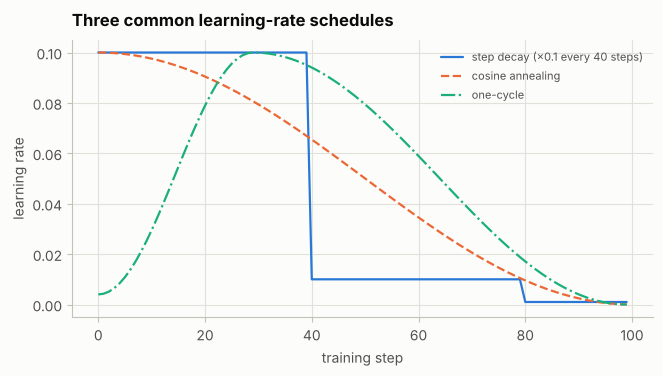

In [19]:
def schedule_values(make_scheduler, steps=100, lr=0.1):
    opt = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=lr)
    scheduler = make_scheduler(opt)
    values = []
    for _ in range(steps):
        values.append(opt.param_groups[0]["lr"])
        opt.step()
        scheduler.step()
    return values


schedules = {
    "step decay (×0.1 every 40 steps)": lambda o: torch.optim.lr_scheduler.StepLR(o, step_size=40, gamma=0.1),
    "cosine annealing": lambda o: torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=100),
    "one-cycle": lambda o: torch.optim.lr_scheduler.OneCycleLR(o, max_lr=0.1, total_steps=100),
}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for (name, make), colour, style in zip(schedules.items(), PALETTE, ["-", "--", "-."]):
    ax.plot(schedule_values(make), color=colour, linestyle=style, label=name)
ax.set_xlabel("training step")
ax.set_ylabel("learning rate")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Three common learning-rate schedules")
plt.show()

Where to call `scheduler.step()` depends on the scheduler: most epoch-based schedules are stepped once per epoch, but `OneCycleLR` and warmup schedules are usually stepped after **every batch**. Check the documentation for the one you use; stepping at the wrong rate silently gives the wrong schedule.

Does a schedule help? Here's the digit MLP with plain SGD and momentum, with and without cosine annealing:

In [20]:
results = {}
for name, use_schedule in [("constant learning rate", False), ("cosine annealing", True)]:
    torch.manual_seed(0)
    m = MLP(64, 128, 10)
    opt = torch.optim.SGD(m.parameters(), lr=0.1, momentum=0.9)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=20) if use_schedule else None
    c = fit(m, epochs=20, optimizer=opt, scheduler=sched)
    results[name] = {"final train loss": c["train loss"][-1], "final valid loss": c["valid loss"][-1], "final valid accuracy": c["valid accuracy"][-1]}
pd.DataFrame(results).T.round(4)

,final train loss,final valid loss,final valid accuracy
constant learning rate,0.0129,0.0727,0.9778
cosine annealing,0.0034,0.0601,0.9778


With the schedule, the final steps are small, so the weights settle into a good spot instead of bouncing around it: the training loss ends lower, and the validation results are usually at least as good. On a problem this small the difference is modest; on large networks trained for many epochs, schedules routinely make a difference of several percentage points.

## 13. GPUs and devices

Neural networks are mostly matrix multiplications, and **graphics cards** (GPUs) do thousands of multiplications in parallel. For large networks, a GPU is often 10 to 100 times faster than a CPU.

In PyTorch, every tensor and every model lives on a **device**. Write code that works on either:

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print("using device:", device)

model = MLP(64, 128, 10).to(device)        # moves every parameter
xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)       # each batch must be moved too
print("output on", model(xb).device)

using device: cpu
output on cpu


`cuda` is an NVIDIA GPU, `mps` is the GPU in recent Apple computers, and `cpu` works everywhere. The rules:

- The model and the data it processes must be on the **same device**; mixing them raises an error ("expected all tensors to be on the same device").
- Move the model once, before creating the optimiser, and move each batch inside the training loop.
- `.item()`, `.numpy()` and printing need the value on the CPU (`.cpu()` brings it back).

**On Colab**, choose *Runtime → Change runtime type → T4 GPU* to get a free GPU. Free GPU time is limited and not guaranteed, so everything in this course is designed to run on a CPU too. For the small networks in this module, a GPU barely helps: moving data back and forth costs as much as the computation saves. GPUs pay off with large models and large batches, such as the image networks in Module 18.

## 14. Debugging training

When a network doesn't learn, the cause is usually one of a short list of bugs, and there's a systematic way to find them. Andrej Karpathy's widely read guide, *A Recipe for Training Neural Networks* (2019), describes this approach.

**1. Check the loss at initialisation.** With 10 classes and random weights, the network should give each class about 1/10 probability, so the cross-entropy should start near `ln(10) ≈ 2.30`. A very different value means something is wrong with the output layer, the loss, or the labels.

In [22]:
torch.manual_seed(0)
fresh = MLP(64, 128, 10)
with torch.no_grad():
    start_loss = nn.CrossEntropyLoss()(fresh(torch.from_numpy(X_tr)), torch.from_numpy(y_tr).long()).item()
print(f"loss at initialisation: {start_loss:.3f}   expected about ln(10) = {np.log(10):.3f}")

loss at initialisation: 2.308   expected about ln(10) = 2.303


**2. Overfit a single batch.** A working network and training loop should be able to memorise one small batch completely: loss near zero, accuracy 100%. If it can't, there's a bug in the model, the loss or the loop, and there's no point training on the full data until it's fixed.

In [23]:
torch.manual_seed(0)
tiny = MLP(64, 128, 10)
opt = torch.optim.Adam(tiny.parameters(), lr=1e-3)
xb, yb = next(iter(train_loader))
for step in range(200):
    opt.zero_grad()
    loss = nn.CrossEntropyLoss()(tiny(xb), yb)
    loss.backward()
    opt.step()
print(f"after 200 steps on one batch of {len(xb)}: loss {loss.item():.5f}, accuracy {(tiny(xb).argmax(1) == yb).float().mean().item():.0%}")

after 200 steps on one batch of 32: loss 0.00213, accuracy 100%


**3. Watch the gradients.** Gradient norms that are tiny (vanishing), huge (exploding) or `nan` point at initialisation, normalisation or the learning rate. A common safety net for exploding gradients is **gradient clipping**: `torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)`, called between `backward()` and `step()`.

In [24]:
torch.manual_seed(0)
probe = MLP(64, 128, 10)
loss = nn.CrossEntropyLoss()(probe(xb), yb)
loss.backward()
for name, p in probe.named_parameters():
    if name.endswith("weight"):
        print(f"{name:<16} gradient norm {p.grad.norm().item():.4f}   weight norm {p.norm().item():.2f}")

hidden1.weight   gradient norm 0.1331   weight norm 6.51
hidden2.weight   gradient norm 0.1768   weight norm 6.54
output.weight    gradient norm 0.1833   weight norm 1.79


**4. The classic bugs.** Here's a buggy training loop with three of the most common mistakes, all of which run without any error:

In [25]:
def buggy_training(model, epochs=10):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for xb, yb in train_loader:
            probabilities = torch.softmax(model(xb), dim=1)     # bug 1: softmax before CrossEntropyLoss
            loss = loss_fn(probabilities, yb)
            loss.backward()                                    # bug 2: gradients never cleared
            optimizer.step()
    model.train()                                              # bug 3: evaluating in training mode (matters with dropout)
    with torch.no_grad():
        return (model(torch.from_numpy(X_va)).argmax(1) == torch.from_numpy(y_va)).float().mean().item()


torch.manual_seed(0)
print(f"buggy loop:   validation accuracy {buggy_training(wide_net(0.5)):.3f}")
torch.manual_seed(0)
fixed = wide_net(0.5)
fit(fixed, epochs=10, optimizer=torch.optim.Adam(fixed.parameters(), lr=1e-3))
print(f"correct loop: validation accuracy {evaluate(fixed, valid_loader, nn.CrossEntropyLoss())[1]:.3f}")

buggy loop:   validation accuracy 0.187


correct loop: validation accuracy 0.967


The buggy version ends up much closer to guessing (10%) than to the correct loop, and nothing in the output says why: no error and no warning. Subtler versions of these bugs (a smaller learning rate, a network without dropout) give results that look plausible, just worse, which is even harder to notice. A checklist for when training goes wrong:

- **Shapes**: print them at every step of `forward`. Watch for silent broadcasting (section 4).
- **Data**: look at a batch: are the inputs scaled, do the labels match the inputs, is the data shuffled?
- **Loss**: raw logits into `CrossEntropyLoss`, integer class labels, a sensible starting value.
- **Loop**: `zero_grad`, `backward`, `step`, in that order, every batch; `model.train()` for training and `model.eval()` with `torch.no_grad()` for evaluation.
- **Learning rate**: try values 10 times larger and smaller.
- **Reproducibility**: set `torch.manual_seed` so a run can be repeated exactly while you debug. (Some GPU operations are still not perfectly repeatable; `torch.use_deterministic_algorithms(True)` makes them so, at some cost in speed.)

## 15. Saving and loading

A trained network is its **parameters**. The recommended way to save it is the **state dict**: a dictionary from parameter names to tensors. To load, create the same architecture and load the dictionary into it.

In [26]:
from pathlib import Path

Path("work").mkdir(exist_ok=True)
torch.save(fixed.state_dict(), "work/digits_mlp.pt")

restored = wide_net(0.5)                                     # the same architecture, fresh weights
restored.load_state_dict(torch.load("work/digits_mlp.pt", weights_only=True))
restored.eval()
print("restored model, validation accuracy:", round(evaluate(restored, valid_loader, nn.CrossEntropyLoss())[1], 3))
print("parameters saved:", list(restored.state_dict().keys()))

restored model, validation accuracy: 0.967
parameters saved: ['0.weight', '0.bias', '3.weight', '3.bias', '6.weight', '6.bias']


Notes:

- Saving the state dict (rather than the whole model object with `torch.save(model)`) keeps the file independent of your code's exact class layout, and it's what model-sharing sites use.
- `weights_only=True` tells `torch.load` to load tensors only. Model files can contain arbitrary Python code that runs when loaded, so **never load a model file from a source you don't trust** without it. (It's the default in recent PyTorch versions.)
- Batch normalisation's running statistics are part of the state dict (as "buffers"), so they're saved too.
- To resume training later, also save the optimiser's state dict and the epoch number.

## Summary

- A **neural network** stacks linear layers and non-linear activations; every weight is learnt by gradient descent using gradients from backpropagation.
- **Tensors** are PyTorch's arrays: NumPy-like, with a dtype (usually `float32`; labels `long`), a shape (batch first) and a device. `from_numpy` shares memory.
- **Autograd** records operations on tensors with `requires_grad=True`; `.backward()` fills `.grad`. Gradients **accumulate**, so clear them every step. Use `torch.no_grad()` when you don't need them.
- The **training loop**: `zero_grad`, forward, loss, `backward`, `step`. Check that predictions and targets have the same shape.
- Networks are `nn.Module` classes (or `nn.Sequential`); data comes from a `Dataset` in mini-batches through a `DataLoader`.
- Classification: the network outputs **logits**; `nn.CrossEntropyLoss` applies the softmax itself.
- **Optimisers**: momentum and Adam/AdamW train far faster than plain SGD. The **learning rate** is the most important setting.
- **Initialisation** (Kaiming, Xavier) keeps signals from vanishing or exploding; **normalisation** (batch, layer) keeps them stable during training. `model.eval()` switches batch norm and dropout to evaluation behaviour.
- **Overfitting**: dropout, weight decay, early stopping, and above all more data.
- **Learning-rate schedules** (step, cosine, warmup, one-cycle) help the final stages of training.
- **Devices**: write device-agnostic code; model and data on the same device. GPUs help most for large models.
- **Debugging**: check the initial loss, overfit one batch, watch gradient norms, and know the classic bugs.
- **Save** the state dict; load with `weights_only=True`.

Next, open `02_exercises.ipynb`.